# 01 · DeFakeNet: paper-faithful reproduction

**Base paper:** D. Samal *et al.*, "DeFakeNet: A ResNet50V2-based deep learning model for deepfake detection and classification", *JIIP* 7(4), 1356–1373, 2025.
**Reported on the test set:** accuracy **91.95 %**, ROC-AUC 97.64 %, PR-AUC 97.40 %, MCC 83.95 %, F1 91.81 % (Real = positive class); 937/1000 fakes and 902/1000 reals correct.

This notebook re-trains DeFakeNet **only from what the paper writes**, with nothing added. It is a separate experiment: it does not read or change the results of notebooks 02 and 03.

## What the paper says, setting by setting

| Setting | Paper (section) | This notebook |
| --- | --- | --- |
| Data | RVF10K balanced splits, Zenodo 10.5281/zenodo.14532968, "60-40" folder = 6,000 / 2,000 / 2,000 (3.1, Table 2) | same |
| Image size | 224 × 224 (3.1) | 224 × 224, Keras default resize (nearest neighbour) |
| Pixel scaling | values changed to the range [0, 1] (3.1) | `rescale = 1/255` |
| Augmentation | rotation up to 10°, 20 % width and height shift, horizontal and vertical flips, 20 % zoom, shearing (3.1) | Keras `ImageDataGenerator` with exactly these values; shear 0.2 (the paper gives no number) |
| Model | ResNet50V2 (ImageNet) → GlobalAveragePooling → Dense 1024 ReLU → Dense 1 sigmoid, 25,664,001 parameters, 195 layers (3.2, Table 3) | same; the backbone is one nested layer, as in Table 3 |
| Fine-tuning | the whole backbone is trainable (3.2) | same |
| Optimiser | Adam, learning rate 1e-4, batch 32, binary cross-entropy (Table 3, 3.3) | same |
| Epochs | at most 40 (3.3) | 40 |
| Early stopping | validation loss, patience 5, best weights kept (3.3, 4) | same |
| Learning-rate schedule | halve the rate when validation loss has not improved for 3 epochs, minimum 1e-6 (3.3) | same (`ReduceLROnPlateau`) |
| Threshold | 0.5 | 0.5 |

## The one point where the paper contradicts itself: BatchNorm

* **Table 3** lists 45,440 non-trainable parameters. In Keras that is exactly the count you get when every BatchNorm layer is **trainable** (only the running mean and variance are non-trainable).
* **Section 3.2** says the BatchNorm layers "were kept **frozen** to maintain stable feature distributions". In Keras, freezing them gives 90,880 non-trainable parameters, not 45,440, and makes BatchNorm use its ImageNet statistics during training.

Both readings can't be true at once, so the notebook trains **both**:

| Variant | BatchNorm | Matches |
| --- | --- | --- |
| `bn_trainable` | trainable (Keras default) | Table 3 (and our first reproduction) |
| `bn_frozen` | frozen, inference mode | the sentence in Section 3.2 |

Each variant is trained with **3 seeds** (42, 1, 2), because one run of this recipe is very noisy (see below).

## How we decide which variant is "the paper's" (without looking at the test set)

The paper describes its training run in Section 4. These numbers come from training and validation only, so we can compare against them without touching the test set:

| Paper's training run | Value |
| --- | --- |
| training accuracy, epoch 1 | 55.65 % |
| training / validation accuracy, epoch 12 | 86.98 % / 82.95 % |
| learning rate first halved | from epoch 13 |
| lowest validation loss | 0.2365 at epoch 29 |
| training stopped | epoch 34 |
| training accuracy at the end | 98.88 % |

The variant whose training runs look most like this is the paper-faithful one. Its test accuracy (mean ± std over 3 seeds) is the reproduction result. We do **not** pick the seed whose test accuracy happens to land closest to 91.95 %; that would be choosing a result to match a target.

## Why single runs of this recipe disagree (89.45 % vs ~96 %)

Two earlier single runs of the same recipe gave 89.45 % and about 96 %; the difference is **when early stopping fired**. With BatchNorm trainable, batch 32 and heavy augmentation, the validation loss jumps around a lot (0.26 → 1.60 → 0.32 in our first run). Early stopping waits only 5 epochs, so a single bad jump can end training very early: our first run stopped at epoch 9 and kept the epoch-4 weights, a model that had trained for only 4 epochs. A run whose validation loss happens not to jump trains much longer and reaches ~96 % or more. The architecture can do much better than 91.95 % (with our recipe it reaches about 98 %), so 91.95 % is where the paper's single run stopped, not a ceiling. That is why this notebook runs 3 seeds and reports the spread.


## 1. Settings

In [1]:
VARIANTS = ["bn_trainable", "bn_frozen"]   # see the table above
SEEDS    = [42, 1, 2]                      # 3 runs per variant -> mean ± std

IMG_SIZE    = 224
BATCH_SIZE  = 32
EPOCHS      = 40          # paper: "a maximum of 40 epochs"
LR          = 1e-4        # Adam
ES_PATIENCE = 5           # early stopping on validation loss
LR_PATIENCE = 3           # ReduceLROnPlateau
LR_FACTOR   = 0.5
MIN_LR      = 1e-6
AUG_WORKERS = 4           # CPU threads that prepare augmented batches

OUTDIR   = "/kaggle/working/paper_repro_output"
CACHEDIR = "/tmp/rvf10k_224"            # decoded images (not saved in the Kaggle output)

PAPER = {"acc": 91.95, "auc": 97.64, "pr_auc": 97.40, "f1": 91.81, "mcc": 83.95,
         "precision": 93.47, "recall": 90.20, "specificity": 93.70,
         "tn": 937, "fp": 63, "fn": 98, "tp": 902}
PAPER_RUN = {"train_acc_ep1": 55.65, "train_acc_ep12": 86.98, "val_acc_ep12": 82.95,
             "first_lr_cut_epoch": 13, "best_epoch": 29, "best_val_loss": 0.2365,
             "stopped_epoch": 34, "final_train_acc": 98.88}

import os, sys, json, time, glob, shutil, subprocess, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
os.makedirs(OUTDIR, exist_ok=True); os.makedirs(CACHEDIR, exist_ok=True)

print(subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True).stdout or "no GPU found")
N_GPUS = len([l for l in subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True).stdout.splitlines() if l.startswith("GPU")])
print("GPUs used:", N_GPUS)
assert N_GPUS >= 1, "Turn on a GPU accelerator (Settings -> Accelerator -> GPU T4 x2)."

GPU 0: Tesla T4 (UUID: GPU-eada999c-6bfb-8573-38a0-b2cb6f7a5ef5)
GPU 1: Tesla T4 (UUID: GPU-7eef0d7e-9060-6f3b-92d6-cccf8f17dbc1)

GPUs used: 2


## 2. Keras 2 (`tf_keras`)

The paper's code is Keras 2 style (`ImageDataGenerator`, the Table 3 summary format, training on Windows with an RTX 3060). Kaggle's TensorFlow ships Keras 3 by default, so the training script uses the Keras 2 package `tf_keras`, which keeps the old behaviour. This cell installs it if it is missing.

In [2]:
tf_ver = subprocess.run([sys.executable, "-c", "import tensorflow as tf; print(tf.__version__)"],
                        capture_output=True, text=True).stdout.strip()
print("TensorFlow:", tf_ver)
has_tfk = subprocess.run([sys.executable, "-c", "import tf_keras"], capture_output=True).returncode == 0
if not has_tfk:
    mm = ".".join(tf_ver.split(".")[:2])
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"tf_keras~={mm}.0"], check=True)
# download the ImageNet weights once here (CPU only), so the two training processes don't both download them
chk = subprocess.run([sys.executable, "-c",
                      "import tf_keras; from tf_keras.applications import ResNet50V2; "
                      "ResNet50V2(include_top=False, weights='imagenet'); print('tf_keras', tf_keras.__version__, '| ResNet50V2 ImageNet weights ready')"],
                     capture_output=True, text=True, env=dict(os.environ, CUDA_VISIBLE_DEVICES=""))
print(chk.stdout.strip() or chk.stderr[-2000:])

TensorFlow: 2.21.0

94668760/94668760 [==============================] - 5s 0us/step
tf_keras 2.21.0 | ResNet50V2 ImageNet weights ready


## 3. Dataset: RVF10K balanced splits (Zenodo), the "60-40" folder

If a copy of the dataset is attached under `/kaggle/input`, it is used; otherwise it is downloaded from Zenodo.

In [3]:
import requests

def find_split_root(base, tokens=("60-40", "60_40", "6040")):
    for root, dirs, _ in os.walk(base):
        if any(t in os.path.basename(root).lower().replace(" ", "") for t in tokens):
            if any(d.lower().startswith("train") for d in dirs):
                return root
    return None

DATA_ROOT = find_split_root("/kaggle/input") if os.path.isdir("/kaggle/input") else None
if DATA_ROOT is None:
    meta = requests.get("https://zenodo.org/api/records/14532968", timeout=60).json()
    os.makedirs("/tmp/data", exist_ok=True)
    for f in meta["files"]:
        dest = f"/tmp/{f['key']}"
        if not os.path.exists(dest):
            print("Downloading", f["key"], f"({f['size']/1e6:.0f} MB) ...")
            subprocess.run(["wget", "-q", "-O", dest, f["links"]["self"]], check=True)
        if f["key"].lower().endswith(".zip") and find_split_root("/tmp/data") is None:
            print("Extracting ...")
            with zipfile.ZipFile(dest) as z:
                z.extractall("/tmp/data")
    DATA_ROOT = find_split_root("/tmp/data")

def pick(parent, names):
    for n in names:
        p = os.path.join(parent, n)
        if os.path.isdir(p): return p
    raise FileNotFoundError(f"none of {names} in {parent}")

SPLITS = {"train": pick(DATA_ROOT, ["train", "training", "Train"]),
          "val":   pick(DATA_ROOT, ["valid", "val", "validation", "Valid"]),
          "test":  pick(DATA_ROOT, ["test", "testing", "Test"])}
print("DATA_ROOT:", DATA_ROOT)
for s, d in SPLITS.items():
    print(f"  {s:5s}", {c: len(os.listdir(os.path.join(d, c))) for c in sorted(os.listdir(d))})

Extracting ...
DATA_ROOT: /tmp/data/Real vs Fake Faces/6040
  train {'fake': 3000, 'real': 3000}
  val   {'fake': 1000, 'real': 1000}
  test  {'fake': 1000, 'real': 1000}


## 4. Decode the images once (identical to `flow_from_directory`)

`flow_from_directory` would decode and resize every image again in every epoch, which is slow. Here each image is decoded **once** with exactly what Keras does inside `flow_from_directory` (convert to RGB, resize to 224 × 224 with nearest-neighbour, the Keras default) and stored. Labels follow Keras's alphabetical order: **fake = 0, real = 1**, so the sigmoid output is P(real) and Real is the positive class, as in the paper. Augmentation is still done fresh for every batch by `ImageDataGenerator`, so training sees the same thing it would with `flow_from_directory`.

In [4]:
EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".ppm", ".tif", ".tiff")

def load_like_keras(path):
    img = Image.open(path)
    if img.mode != "RGB":
        img = img.convert("RGB")
    if img.size != (IMG_SIZE, IMG_SIZE):
        img = img.resize((IMG_SIZE, IMG_SIZE), Image.NEAREST)
    return np.asarray(img, dtype=np.uint8)

for split, d in SPLITS.items():
    xp, yp = f"{CACHEDIR}/x_{split}.npy", f"{CACHEDIR}/y_{split}.npy"
    if os.path.exists(xp) and os.path.exists(yp):
        continue
    classes = sorted(c for c in os.listdir(d) if os.path.isdir(os.path.join(d, c)))
    assert classes == ["fake", "real"], classes
    files, labels = [], []
    for ci, c in enumerate(classes):
        fs = sorted(f for f in os.listdir(os.path.join(d, c)) if f.lower().endswith(EXTS))
        files += [os.path.join(d, c, f) for f in fs]; labels += [ci] * len(fs)
    with ThreadPoolExecutor(8) as ex:
        x = np.stack(list(ex.map(load_like_keras, files)))
    np.save(xp, x); np.save(yp, np.array(labels, dtype=np.float32))
    print(f"{split:5s} {x.shape}  fake={labels.count(0)} real={labels.count(1)}")

for split in SPLITS:
    print(split, np.load(f"{CACHEDIR}/x_{split}.npy", mmap_mode="r").shape)

train (6000, 224, 224, 3)  fake=3000 real=3000
val   (2000, 224, 224, 3)  fake=1000 real=1000
test  (2000, 224, 224, 3)  fake=1000 real=1000
train (6000, 224, 224, 3)
val (2000, 224, 224, 3)
test (2000, 224, 224, 3)


## 5. The training script

One run = one variant + one seed. The script is written to a file and started as a separate process per GPU, so the two variants can train side by side on the two T4s. Everything inside follows the paper; the comments give the section.

In [5]:
SCRIPT = r"""
import os, sys, json, time, argparse, random
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import tensorflow as tf
import tf_keras as keras
from tf_keras import layers
from tf_keras.applications import ResNet50V2
from tf_keras.preprocessing.image import ImageDataGenerator
from tf_keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, CSVLogger
from sklearn.metrics import (roc_auc_score, average_precision_score, matthews_corrcoef,
                             confusion_matrix, f1_score, precision_score, recall_score)

ap = argparse.ArgumentParser()
for k in ["variant", "cache", "outdir"]: ap.add_argument("--" + k, required=True)
for k in ["seed", "epochs", "batch", "img", "es_patience", "lr_patience", "workers"]:
    ap.add_argument("--" + k, type=int, required=True)
for k in ["lr", "lr_factor", "min_lr"]: ap.add_argument("--" + k, type=float, required=True)
a = ap.parse_args()
key = f"DeFakeNet_paper__{a.variant}__s{a.seed}"
freeze_bn = {"bn_trainable": False, "bn_frozen": True}[a.variant]

for g in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(g, True)
random.seed(a.seed); np.random.seed(a.seed); tf.random.set_seed(a.seed)

# ---- data: 224x224, [0,1] scaling, paper's augmentation (Sec. 3.1) ----
x_tr = np.load(f"{a.cache}/x_train.npy"); y_tr = np.load(f"{a.cache}/y_train.npy")
x_va = np.load(f"{a.cache}/x_val.npy").astype("float32") / 255.0; y_va = np.load(f"{a.cache}/y_val.npy")
x_te = np.load(f"{a.cache}/x_test.npy").astype("float32") / 255.0; y_te = np.load(f"{a.cache}/y_test.npy")
train_aug = ImageDataGenerator(rescale=1.0 / 255.0, rotation_range=10, width_shift_range=0.2,
                               height_shift_range=0.2, shear_range=0.2, zoom_range=0.2,
                               horizontal_flip=True, vertical_flip=True, fill_mode="nearest")
train_it = train_aug.flow(x_tr, y_tr, batch_size=a.batch, shuffle=True, seed=a.seed)
del x_tr

# ---- model: Table 3 / Sec. 3.2 ----
inp = layers.Input(shape=(a.img, a.img, 3), name="InputLayer")
base = ResNet50V2(include_top=False, weights="imagenet", input_shape=(a.img, a.img, 3))
base.trainable = True                                   # the entire base model is fine-tuned
if freeze_bn:                                           # Sec. 3.2 sentence: BatchNorm kept frozen
    for l in base.layers:
        if isinstance(l, layers.BatchNormalization):
            l.trainable = False
x = base(inp)
x = layers.GlobalAveragePooling2D(name="global_average_pooling2d")(x)
x = layers.Dense(1024, activation="relu", name="dense")(x)
out = layers.Dense(1, activation="sigmoid", name="dense_1")(x)
model = keras.Model(inp, out, name="DeFakeNet")
model.compile(optimizer=keras.optimizers.Adam(learning_rate=a.lr),
              loss="binary_crossentropy", metrics=["accuracy"])
n_tr = int(sum(np.prod(w.shape) for w in model.trainable_weights))
n_all = model.count_params()
print(f"[{key}] params total {n_all:,} | trainable {n_tr:,} | non-trainable {n_all - n_tr:,} | "
      f"layers {len(base.layers) + len(model.layers)}", flush=True)

# ---- training: Sec. 3.3 ----
ckpt = f"{a.outdir}/{key}_best.weights.h5"
cbs = [EarlyStopping(monitor="val_loss", patience=a.es_patience, restore_best_weights=True, verbose=1),
       ReduceLROnPlateau(monitor="val_loss", factor=a.lr_factor, patience=a.lr_patience,
                         min_lr=a.min_lr, verbose=1),
       ModelCheckpoint(ckpt, monitor="val_loss", save_best_only=True, save_weights_only=True, verbose=0),
       CSVLogger(f"{a.outdir}/{key}_epochs.csv")]
t0 = time.time()
hist = model.fit(train_it, validation_data=(x_va, y_va), validation_batch_size=a.batch, epochs=a.epochs,
                 callbacks=cbs, workers=a.workers, use_multiprocessing=False, verbose=2)
train_s = time.time() - t0
h = {k: [float(v) for v in vals] for k, vals in hist.history.items()}
model.load_weights(ckpt)                                # weights of the lowest validation loss

# ---- test: threshold 0.5, Real = positive (Sec. 4) ----
p = model.predict(x_te, batch_size=a.batch, verbose=0).ravel()
yt = y_te.astype(int); yp = (p >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(yt, yp).ravel()
t1 = time.time()
for _ in range(5): model.predict(x_te[:320], batch_size=a.batch, verbose=0)
ms = (time.time() - t1) / (5 * 320) * 1000

best = int(np.argmin(h["val_loss"]))
lrs = h.get("lr", h.get("learning_rate", [a.lr] * len(h["loss"])))
cut = next((i + 1 for i, v in enumerate(lrs) if v < a.lr * 0.99), None)
res = {
    "key": key, "variant": a.variant, "seed": a.seed, "freeze_bn": freeze_bn,
    "params_total": int(n_all), "params_trainable": n_tr, "params_non_trainable": int(n_all - n_tr),
    "epochs_run": len(h["loss"]), "train_seconds": round(train_s, 1),
    "run": {"train_acc_ep1": round(h["accuracy"][0] * 100, 2),
            "train_acc_ep12": round(h["accuracy"][11] * 100, 2) if len(h["accuracy"]) >= 12 else None,
            "val_acc_ep12": round(h["val_accuracy"][11] * 100, 2) if len(h["val_accuracy"]) >= 12 else None,
            "first_lr_cut_epoch": cut, "best_epoch": best + 1,
            "best_val_loss": round(h["val_loss"][best], 4),
            "val_acc_at_best": round(h["val_accuracy"][best] * 100, 2),
            "stopped_epoch": len(h["loss"]), "final_train_acc": round(h["accuracy"][-1] * 100, 2)},
    "test": {"acc": round(100 * (tp + tn) / len(yt), 2), "auc": round(100 * roc_auc_score(yt, p), 2),
             "pr_auc": round(100 * average_precision_score(yt, p), 2),
             "f1": round(100 * f1_score(yt, yp), 2), "mcc": round(100 * matthews_corrcoef(yt, yp), 2),
             "precision": round(100 * precision_score(yt, yp), 2), "recall": round(100 * recall_score(yt, yp), 2),
             "specificity": round(100 * tn / (tn + fp), 2),
             "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    "ms_per_img": round(ms, 2), "history": h,
}
np.savez_compressed(f"{a.outdir}/{key}_probs.npz", probs=p, y=yt)
json.dump(res, open(f"{a.outdir}/{key}_results.json", "w"), indent=1)
print(f"[{key}] DONE test acc {res['test']['acc']:.2f} | AUC {res['test']['auc']:.2f} | "
      f"best epoch {best + 1} | stopped {len(h['loss'])}", flush=True)
"""
open(f"{OUTDIR}/train_one.py", "w").write(SCRIPT)
print("written", f"{OUTDIR}/train_one.py")

written /kaggle/working/paper_repro_output/train_one.py


## 6. Train all runs

Runs are split over the GPUs (variant `bn_trainable` on GPU 0, `bn_frozen` on GPU 1 when there are two). Progress is printed every 5 minutes. A run whose results file already exists is skipped.

In [6]:
def key_of(v, s): return f"DeFakeNet_paper__{v}__s{s}"

pending = [(v, s) for s in SEEDS for v in VARIANTS
        if not os.path.exists(f"{OUTDIR}/{key_of(v, s)}_results.json")]
queues = {g: [] for g in range(N_GPUS)}
for v, s in pending:
    queues[VARIANTS.index(v) % N_GPUS].append((v, s))
print("to train:", pending or "nothing, all runs already done")

args_common = (f"--cache {CACHEDIR} --outdir {OUTDIR} --epochs {EPOCHS} --batch {BATCH_SIZE} --img {IMG_SIZE} "
               f"--es_patience {ES_PATIENCE} --lr_patience {LR_PATIENCE} --workers {AUG_WORKERS} "
               f"--lr {LR} --lr_factor {LR_FACTOR} --min_lr {MIN_LR}")
procs = {}
for g, q in queues.items():
    if not q: continue
    cmds = [f"{sys.executable} {OUTDIR}/train_one.py --variant {v} --seed {s} {args_common} "
            f"> {OUTDIR}/{key_of(v, s)}.log 2>&1" for v, s in q]
    env = dict(os.environ, CUDA_VISIBLE_DEVICES=str(g))
    procs[g] = subprocess.Popen(["bash", "-c", " ; ".join(cmds)], env=env)
    print(f"GPU {g}:", [key_of(v, s) for v, s in q])

def progress():
    for v, s in pending:
        k = key_of(v, s); csv = f"{OUTDIR}/{k}_epochs.csv"
        if os.path.exists(f"{OUTDIR}/{k}_results.json"):
            r = json.load(open(f"{OUTDIR}/{k}_results.json"))
            print(f"  {k:38s} done: test acc {r['test']['acc']:.2f}, stopped at epoch {r['epochs_run']}")
        elif os.path.exists(csv) and os.path.getsize(csv) > 0:
            d = pd.read_csv(csv)
            if len(d):
                last = d.iloc[-1]
                print(f"  {k:38s} epoch {len(d):2d}: train acc {last['accuracy']*100:.2f} | "
                      f"val loss {last['val_loss']:.4f} | val acc {last['val_accuracy']*100:.2f}")
        else:
            print(f"  {k:38s} waiting / starting")

t0 = time.time()
while procs and any(p.poll() is None for p in procs.values()):
    time.sleep(300)
    print(f"--- {(time.time() - t0) / 60:.0f} min ---"); progress()
print("all training finished in", f"{(time.time() - t0) / 60:.0f} min")
for v, s in pending:
    k = key_of(v, s)
    if not os.path.exists(f"{OUTDIR}/{k}_results.json"):
        print(f"\n!!! {k} failed, last lines of its log:")
        print("".join(open(f"{OUTDIR}/{k}.log").readlines()[-25:]))

to train: [('bn_trainable', 42), ('bn_frozen', 42), ('bn_trainable', 1), ('bn_frozen', 1), ('bn_trainable', 2), ('bn_frozen', 2)]
GPU 0: ['DeFakeNet_paper__bn_trainable__s42', 'DeFakeNet_paper__bn_trainable__s1', 'DeFakeNet_paper__bn_trainable__s2']
GPU 1: ['DeFakeNet_paper__bn_frozen__s42', 'DeFakeNet_paper__bn_frozen__s1', 'DeFakeNet_paper__bn_frozen__s2']
--- 5 min ---
  DeFakeNet_paper__bn_trainable__s42     epoch  2: train acc 84.90 | val loss 0.3507 | val acc 84.95
  DeFakeNet_paper__bn_frozen__s42        epoch  2: train acc 51.58 | val loss 0.6934 | val acc 50.00
  DeFakeNet_paper__bn_trainable__s1      waiting / starting
  DeFakeNet_paper__bn_frozen__s1         waiting / starting
  DeFakeNet_paper__bn_trainable__s2      waiting / starting
  DeFakeNet_paper__bn_frozen__s2         waiting / starting
--- 10 min ---
  DeFakeNet_paper__bn_trainable__s42     epoch  5: train acc 91.92 | val loss 0.7657 | val acc 77.65
  DeFakeNet_paper__bn_frozen__s42        epoch  6: train acc 60.65 

## 7. Results

### 7.1 Does the model match Table 3?

In [7]:
R = {}
for f in sorted(glob.glob(f"{OUTDIR}/DeFakeNet_paper__*_results.json")):
    r = json.load(open(f)); R[r["key"]] = r
assert R, "no finished runs found"
rows = [{"variant": v, "total": "25,664,001", "trainable": "25,618,561", "non-trainable": "45,440", "source": "paper Table 3"}]
for v in VARIANTS:
    r = next((r for r in R.values() if r["variant"] == v), None)
    if r: rows.append({"variant": v, "total": f"{r['params_total']:,}", "trainable": f"{r['params_trainable']:,}",
                       "non-trainable": f"{r['params_non_trainable']:,}", "source": "this notebook"})
display(pd.DataFrame(rows))

,variant,total,trainable,non-trainable,source
0,bn_frozen,"25,664,001","25,618,561","45,440",paper Table 3
1,bn_trainable,"25,664,001","25,618,561","45,440",this notebook
2,bn_frozen,"25,664,001","25,573,121","90,880",this notebook


### 7.2 Which variant trains like the paper? (training and validation only, no test numbers)

Each run is compared with the paper's training run from Section 4. `distance` is the average relative gap over the eight numbers (0 = identical). The variant with the smaller mean distance is taken as the paper-faithful one.

In [8]:
def distance(run):
    gaps = []
    for k, ref in PAPER_RUN.items():
        v = run.get(k)
        if v is None:                      # e.g. stopped before epoch 12: counts as a full miss
            gaps.append(1.0); continue
        gaps.append(min(abs(v - ref) / abs(ref), 1.0))
    return float(np.mean(gaps))

rows = [dict(run="PAPER", **PAPER_RUN, distance=0.0)]
for k, r in R.items():
    rows.append(dict(run=k, **{c: r["run"].get(c) for c in PAPER_RUN}, distance=round(distance(r["run"]), 3)))
T_RUN = pd.DataFrame(rows).set_index("run")
display(T_RUN)

dist_by_variant = {v: np.mean([distance(r["run"]) for r in R.values() if r["variant"] == v])
                   for v in VARIANTS if any(r["variant"] == v for r in R.values())}
FAITHFUL = min(dist_by_variant, key=dist_by_variant.get)
print("mean distance per variant:", {k: round(v, 3) for k, v in dist_by_variant.items()})
print("=> paper-faithful variant (chosen on training behaviour only):", FAITHFUL)

,train_acc_ep1,train_acc_ep12,val_acc_ep12,first_lr_cut_epoch,best_epoch,best_val_loss,stopped_epoch,final_train_acc,distance
run,,,,,,,,,
PAPER,55.65,86.98,82.95,13,29,0.2365,34,98.88,0.000
DeFakeNet_paper__bn_frozen__s1,52.02,83.52,81.40,20,26,0.2622,31,97.35,0.122
DeFakeNet_paper__bn_frozen__s2,50.73,86.55,85.40,14,21,0.2300,26,97.78,0.094
DeFakeNet_paper__bn_frozen__s42,50.87,79.47,78.95,27,23,0.3007,28,94.17,0.240
DeFakeNet_paper__bn_trainable__s1,73.48,NaN,NaN,9,5,0.1869,10,96.50,0.549
DeFakeNet_paper__bn_trainable__s2,73.47,96.70,89.20,12,8,0.2167,13,97.08,0.253
DeFakeNet_paper__bn_trainable__s42,73.25,NaN,NaN,6,6,0.1531,11,97.67,0.586


mean distance per variant: {'bn_trainable': np.float64(0.463), 'bn_frozen': np.float64(0.152)}
=> paper-faithful variant (chosen on training behaviour only): bn_frozen


### 7.3 Test results (threshold 0.5, Real = positive class)

In [9]:
cols = ["acc", "auc", "pr_auc", "f1", "mcc", "precision", "recall", "specificity", "tn", "fp", "fn", "tp"]
rows = [dict(run="PAPER (reported)", **{c: PAPER[c] for c in cols})]
for k, r in R.items():
    rows.append(dict(run=k, **{c: r["test"][c] for c in cols}, ms_per_img=r["ms_per_img"],
                     epochs=r["epochs_run"], best_epoch=r["run"]["best_epoch"]))
T_TEST = pd.DataFrame(rows).set_index("run")
display(T_TEST)

summary = []
for v in VARIANTS:
    rs = [r for r in R.values() if r["variant"] == v]
    if not rs: continue
    row = {"variant": v, "runs": len(rs)}
    for c in ["acc", "auc", "pr_auc", "f1", "mcc"]:
        vals = np.array([r["test"][c] for r in rs])
        row[c] = f"{vals.mean():.2f} ± {vals.std(ddof=1) if len(vals) > 1 else 0:.2f}"
        if c == "acc":
            row["acc range"] = f"{vals.min():.2f} – {vals.max():.2f}"
            row["91.95 inside range?"] = "yes" if vals.min() <= PAPER["acc"] <= vals.max() else "no"
    summary.append(row)
T_SUM = pd.DataFrame(summary).set_index("variant")
display(T_SUM)
print(f"Paper reported: acc {PAPER['acc']} | ROC-AUC {PAPER['auc']} | PR-AUC {PAPER['pr_auc']} | "
      f"F1 {PAPER['f1']} | MCC {PAPER['mcc']}")
print(f"Paper-faithful variant: {FAITHFUL} -> test accuracy {T_SUM.loc[FAITHFUL, 'acc']} over {T_SUM.loc[FAITHFUL, 'runs']} seeds")

,acc,auc,pr_auc,f1,mcc,precision,recall,specificity,tn,fp,fn,tp,ms_per_img,epochs,best_epoch
run,,,,,,,,,,,,,,,
PAPER (reported),91.95,97.64,97.40,91.81,83.95,93.47,90.2,93.7,937,63,98,902,NaN,NaN,NaN
DeFakeNet_paper__bn_frozen__s1,91.15,97.09,97.13,91.10,82.30,91.61,90.6,91.7,917,83,94,906,4.46,31.0,26.0
DeFakeNet_paper__bn_frozen__s2,92.40,97.67,97.64,92.41,84.80,92.32,92.5,92.3,923,77,75,925,4.46,26.0,21.0
DeFakeNet_paper__bn_frozen__s42,88.15,94.87,94.66,88.30,76.32,87.22,89.4,86.9,869,131,106,894,4.50,28.0,23.0
DeFakeNet_paper__bn_trainable__s1,93.10,97.84,97.73,93.26,86.30,91.13,95.5,90.7,907,93,45,955,4.96,10.0,5.0
DeFakeNet_paper__bn_trainable__s2,90.75,96.94,97.01,90.86,81.53,89.76,92.0,89.5,895,105,80,920,5.23,13.0,8.0
DeFakeNet_paper__bn_trainable__s42,94.55,98.92,98.98,94.52,89.11,95.05,94.0,95.1,951,49,60,940,5.99,11.0,6.0


,runs,acc,acc range,91.95 inside range?,auc,pr_auc,f1,mcc
variant,,,,,,,,
bn_trainable,3,92.80 ± 1.92,90.75 – 94.55,yes,97.90 ± 0.99,97.91 ± 1.00,92.88 ± 1.86,85.65 ± 3.83
bn_frozen,3,90.57 ± 2.18,88.15 – 92.40,yes,96.54 ± 1.48,96.48 ± 1.59,90.60 ± 2.10,81.14 ± 4.36


Paper reported: acc 91.95 | ROC-AUC 97.64 | PR-AUC 97.4 | F1 91.81 | MCC 83.95
Paper-faithful variant: bn_frozen -> test accuracy 90.57 ± 2.18 over 3 seeds


### 7.4 Training curves (compare with Figure 4 of the paper)

Dotted grey lines mark the paper's run: best epoch 29 and stop at epoch 34.

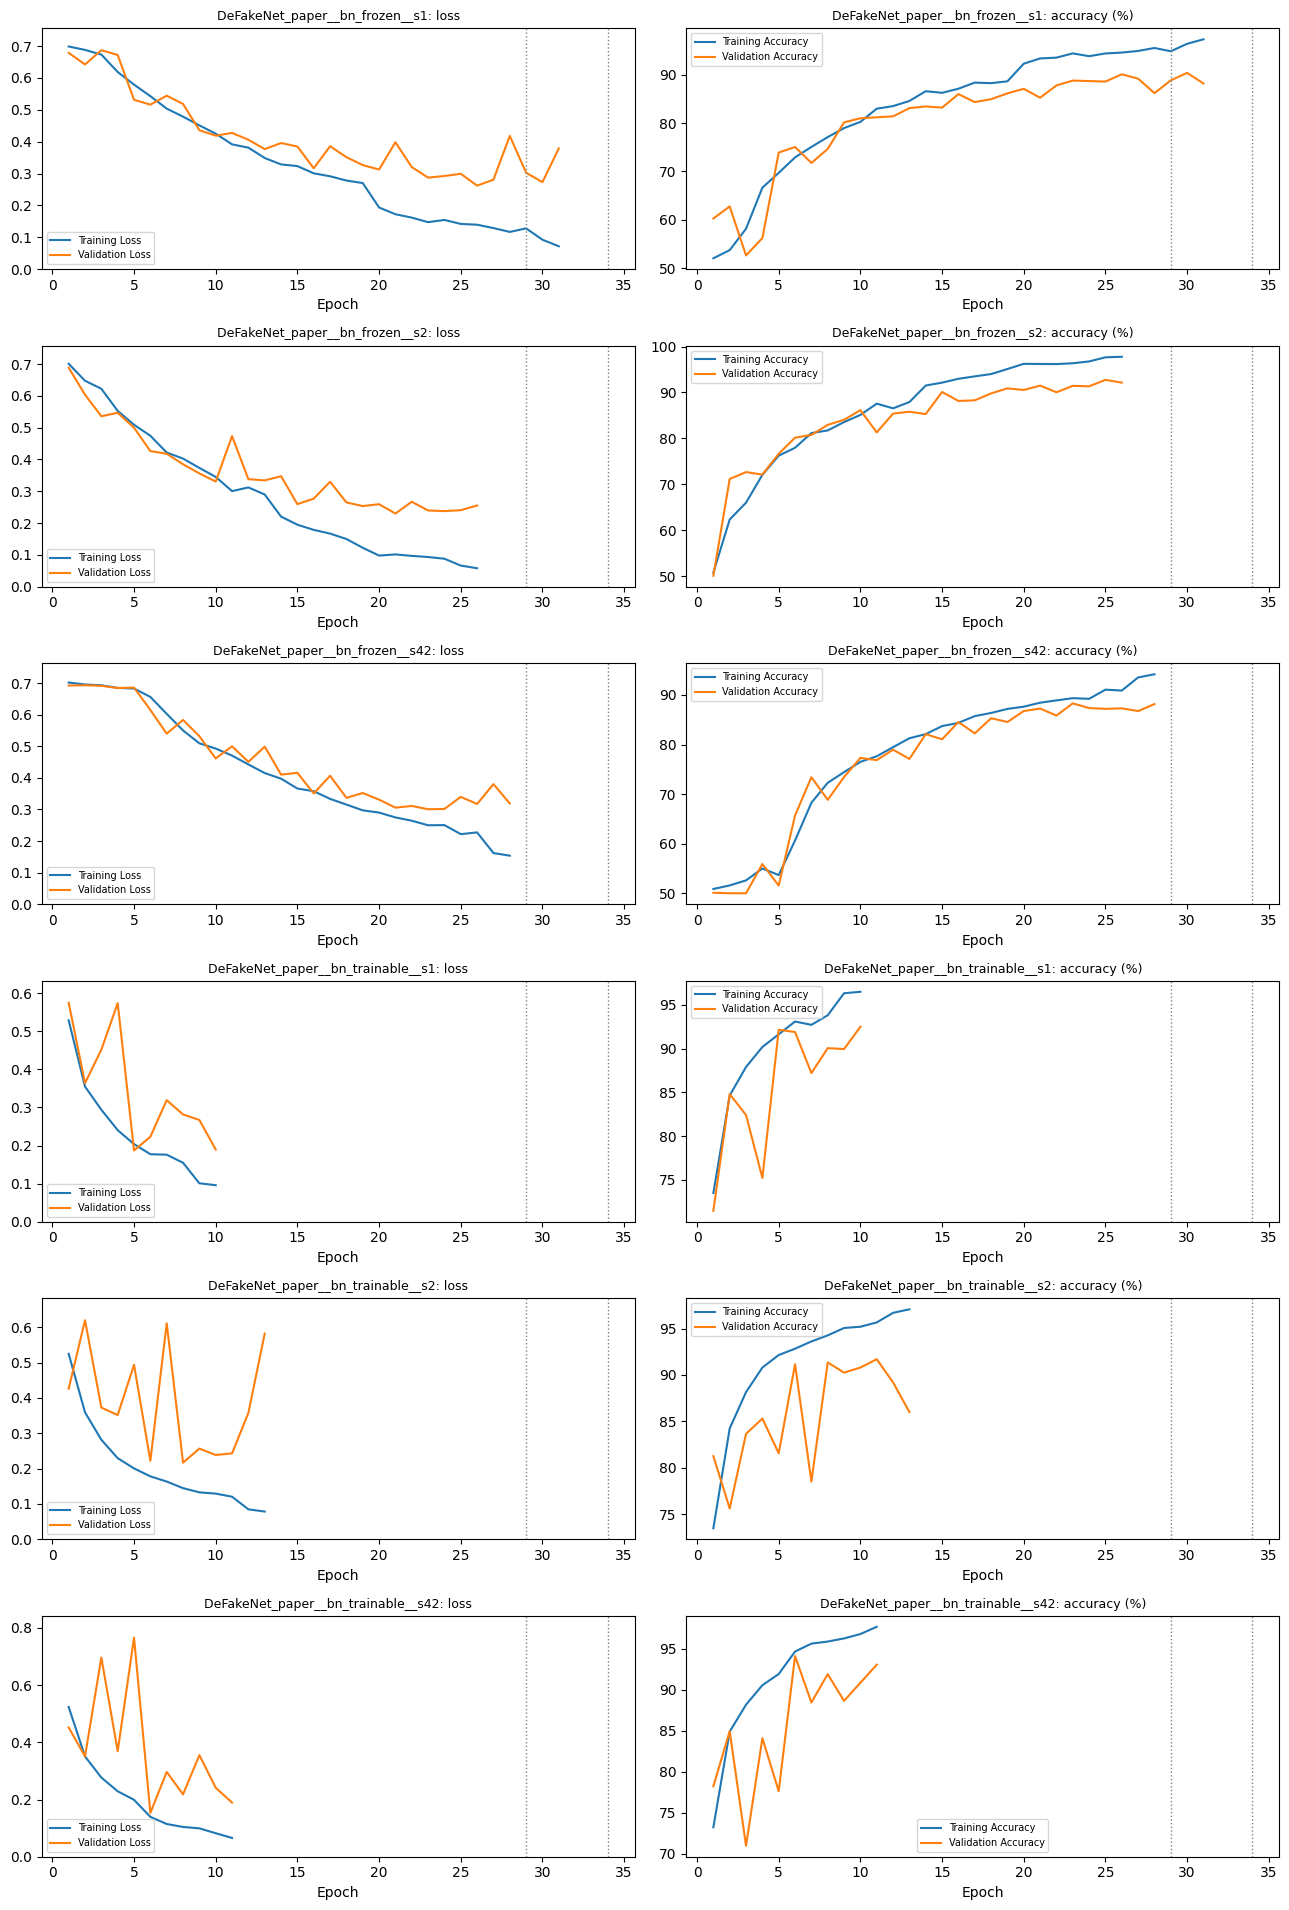

In [10]:
keys = sorted(R)
fig, axes = plt.subplots(len(keys), 2, figsize=(13, 3.2 * len(keys)), squeeze=False)
for row, k in zip(axes, keys):
    h = R[k]["history"]; ep = np.arange(1, len(h["loss"]) + 1)
    row[0].plot(ep, h["loss"], label="Training Loss"); row[0].plot(ep, h["val_loss"], label="Validation Loss")
    row[1].plot(ep, np.array(h["accuracy"]) * 100, label="Training Accuracy")
    row[1].plot(ep, np.array(h["val_accuracy"]) * 100, label="Validation Accuracy")
    for ax, t in zip(row, ["loss", "accuracy (%)"]):
        for e in (29, 34): ax.axvline(e, color="grey", ls=":", lw=1)
        ax.set_title(f"{k}: {t}", fontsize=9); ax.set_xlabel("Epoch"); ax.legend(fontsize=7)
    row[0].set_ylim(0, min(2.0, max(h["val_loss"]) * 1.1))
plt.tight_layout(); plt.savefig(f"{OUTDIR}/training_curves_all_runs.png", dpi=200); plt.show()

### 7.5 Confusion matrix, ROC and PR curves of the paper-faithful variant (seed 42, or the first finished seed)

Compare with Figures 5 and 6 of the paper.

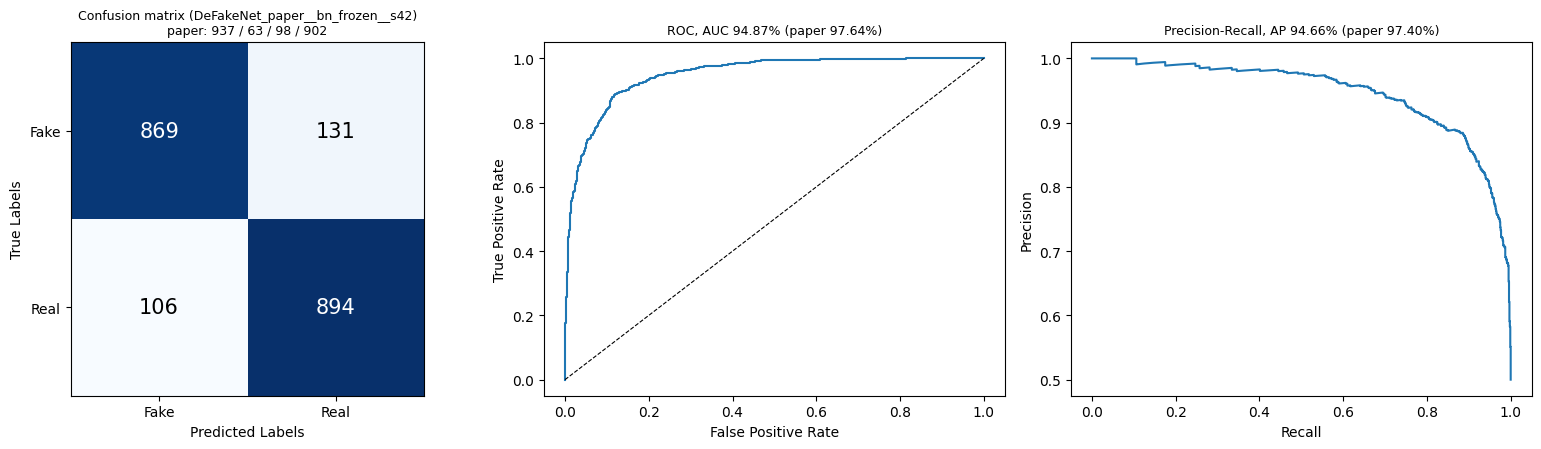

In [11]:
from sklearn.metrics import roc_curve, precision_recall_curve
fk = [k for k in keys if R[k]["variant"] == FAITHFUL]
k = next((x for x in fk if x.endswith("__s42")), fk[0])
d = np.load(f"{OUTDIR}/{k}_probs.npz"); p, y = d["probs"], d["y"]
t = R[k]["test"]; cm = np.array([[t["tn"], t["fp"]], [t["fn"], t["tp"]]])

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
ax[0].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, cm[i, j], ha="center", va="center", fontsize=15,
                   color="white" if cm[i, j] > cm.max() / 2 else "black")
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(["Fake", "Real"]); ax[0].set_yticks([0, 1]); ax[0].set_yticklabels(["Fake", "Real"])
ax[0].set_xlabel("Predicted Labels"); ax[0].set_ylabel("True Labels")
ax[0].set_title(f"Confusion matrix ({k})\npaper: 937 / 63 / 98 / 902", fontsize=9)
fpr, tpr, _ = roc_curve(y, p); ax[1].plot(fpr, tpr); ax[1].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[1].set_title(f"ROC, AUC {t['auc']:.2f}% (paper 97.64%)", fontsize=9); ax[1].set_xlabel("False Positive Rate"); ax[1].set_ylabel("True Positive Rate")
pr, rc, _ = precision_recall_curve(y, p); ax[2].plot(rc, pr)
ax[2].set_title(f"Precision-Recall, AP {t['pr_auc']:.2f}% (paper 97.40%)", fontsize=9); ax[2].set_xlabel("Recall"); ax[2].set_ylabel("Precision")
plt.tight_layout(); plt.savefig(f"{OUTDIR}/faithful_cm_roc_pr.png", dpi=200); plt.show()

## 8. Save everything

`paper_repro_results.zip` holds every run's results JSON (numbers, training history, settings), test scores (`_probs.npz`), per-epoch CSV, log, the tables and the figures. The model weights stay in the output folder but are left out of the zip (about 100 MB each).

In [12]:
T_RUN.to_csv(f"{OUTDIR}/table_training_vs_paper.csv")
T_TEST.to_csv(f"{OUTDIR}/table_test_all_runs.csv")
T_SUM.to_csv(f"{OUTDIR}/table_test_mean_std.csv")
json.dump({"faithful_variant": FAITHFUL, "distance_by_variant": dist_by_variant,
           "paper": PAPER, "paper_run": PAPER_RUN}, open(f"{OUTDIR}/summary.json", "w"), indent=1)
zp = "/kaggle/working/paper_repro_results.zip"
with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(glob.glob(f"{OUTDIR}/*")):
        if not f.endswith(".h5"):
            z.write(f, os.path.basename(f))
print("saved", zp, f"({os.path.getsize(zp) / 1e6:.1f} MB)")

saved /kaggle/working/paper_repro_results.zip (0.8 MB)
